In [2]:
!pip install mne
import os
import numpy as np
import mne
import pandas
import ipykernel

import matplotlib.pyplot as plt


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import shutil
import os
def extract_zip(zip_file, extract_to):
    try:
        shutil.unpack_archive(zip_file, extract_to, 'zip')
        print("Extraction complete.")
    except Exception as e:
        print(f"Error: {e}")

zip_file = "/content/drive/MyDrive/data new.zip"
extract_to = "/content/data"

# Check if the zip file exists
if not os.path.exists(zip_file):
    print("Error: The specified ZIP file does not exist.")
    exit()

    # Check if the extract directory exists, if not, create it
if not os.path.exists(extract_to):
    os.makedirs(extract_to)

extract_zip(zip_file, extract_to)


Extraction complete.


In [16]:
import mne
file = "/content/data/data new/Patient data/P201006.edf"
raw = mne.io.read_raw_edf(file,preload=True)
raw_data = raw.get_data()
print(raw_data)
# plt.plot(raw_data)

# you can get the metadata included in the file and a list of all channels:
info = raw.info
channels = raw.ch_names
print(channels)
raw_data.shape

Extracting EDF parameters from /content/data/data new/Patient data/P201006.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 181999  =      0.000 ...   909.995 secs...
[[-5.68322334e-05  3.60336321e-09  3.60336321e-09 ...  4.10515859e-06
  -3.87020945e-07 -6.63700987e-06]
 [-7.52933844e-05 -4.25650909e-10 -4.25650909e-10 ...  3.28120700e-05
   3.64253508e-05  2.93941017e-05]
 [-1.03513892e-04  1.66901444e-09  1.66901444e-09 ...  4.67789839e-05
   4.71696087e-05  4.29703925e-05]
 ...
 [-5.18555817e-05 -1.14851548e-10 -1.14851548e-10 ...  5.93748830e-05
   5.92772268e-05  5.73241018e-05]
 [-1.20029000e+01 -1.20029000e+01 -1.20029000e+01 ... -1.15029000e+01
  -1.15029000e+01 -1.15029000e+01]
 [-1.20029000e+01 -1.20029000e+01 -1.20029000e+01 ... -1.20029000e+01
  -1.20029000e+01 -1.20029000e+01]]
['EEG Fp1-Ref', 'EEG F3-Ref', 'EEG C3-Ref', 'EEG P3-Ref', 'EEG O1-Ref', 'EEG F7-Ref', 'EEG T3-Ref', 'EEG T5-Ref', 'EEG A1-Ref', 'POL EMG+', 'P

(28, 182000)

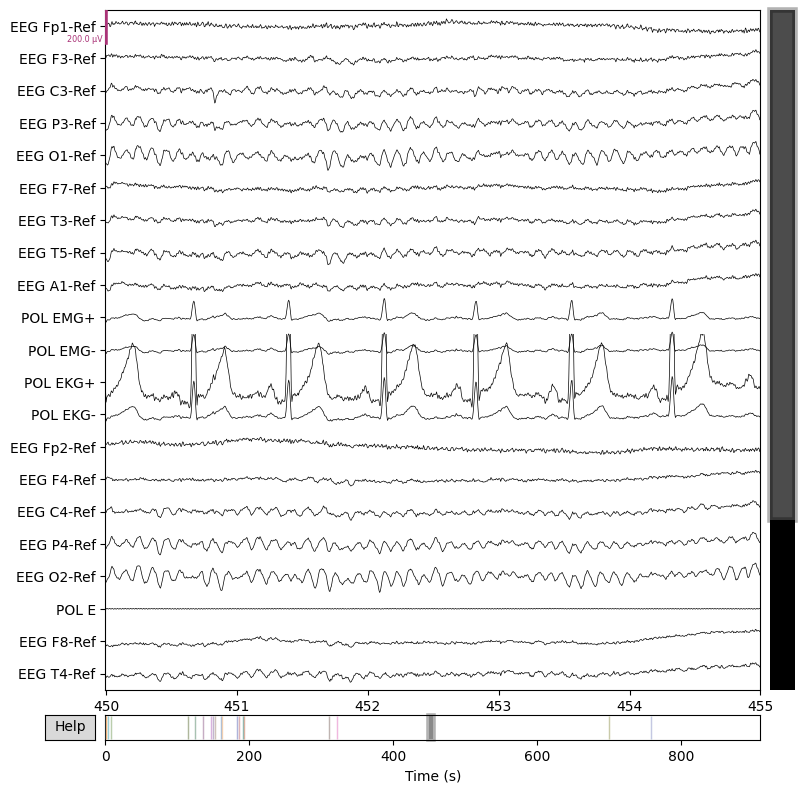

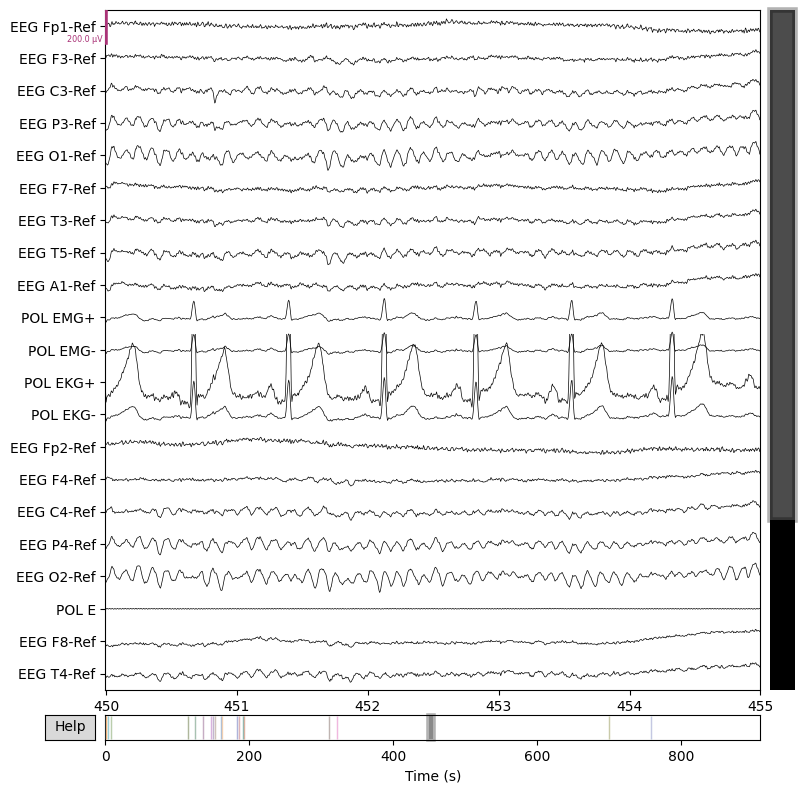

In [17]:
midpoint = raw.times[-1] / 2  # Total duration divided by 2
# Plot from the midpoint
raw.plot(duration=5, n_channels=21, block=True, scalings=0.0001, start=midpoint - 5)  # 5 seconds before the midpoint


In [ ]:
raw.info['custom_ref_applied']

In [ ]:
print(raw.get_montage())


In [ ]:
# mean = np.mean(raw_data, axis=1, keepdims=True)
# std = np.std(raw_data, axis=1, keepdims=True)
# normalized_data = (raw_data - mean) / std

# # Update the raw object with normalized data
# raw._data = normalized_data

In [ ]:
# raw.set_eeg_reference(ref_channels='average')

# midpoint = raw.times[-1] / 2  # Total duration divided by 2
# # Plot from the midpoint
# raw.plot(duration=5, n_channels=19, block=True, scalings=0.0001, start=midpoint - 5)

In [18]:
raw.notch_filter(50)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 1321 samples (6.605 s)



[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.1s


<RawEDF | P201006.edf, 28 x 182000 (910.0 s), ~38.9 MiB, data loaded>

In [19]:
from scipy.signal import butter, lfilter

# Define a function for the Butterworth bandpass filter
def butter_bandpass(lowcut, highcut, fs, order=4):
    nyquist = 0.5 * fs  # Nyquist frequency
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='bandpass')
    return b, a

def bandpass_filter(data, lowcut, highcut, fs, order=4):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    filtered_data = lfilter(b, a, data, axis=1)
    return filtered_data

# Extract data and sampling frequency
raw_data = raw.get_data()  # Shape: (n_channels, n_samples)
fs = int(raw.info['sfreq'])  # Sampling frequency

# Define filter parameters
lowcut = 0.5  # Lower bound of the bandpass filter in Hz
highcut = 50  # Upper bound of the bandpass filter in Hz

# Apply the filter to the raw data
filtered_data = bandpass_filter(raw_data, lowcut, highcut, fs, order=4)

# Update the raw object with filtered data
raw._data = filtered_data



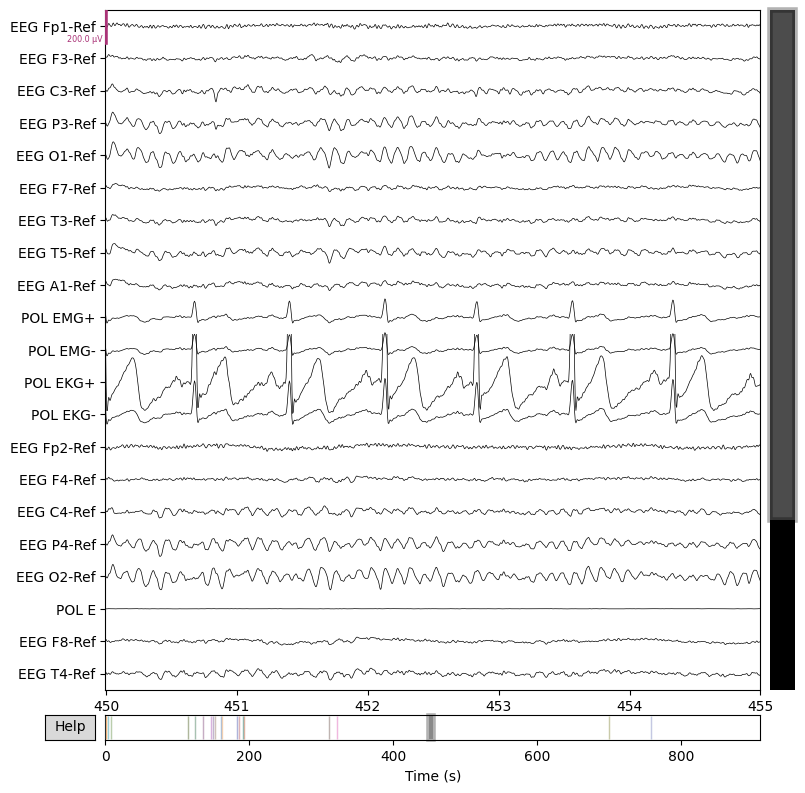

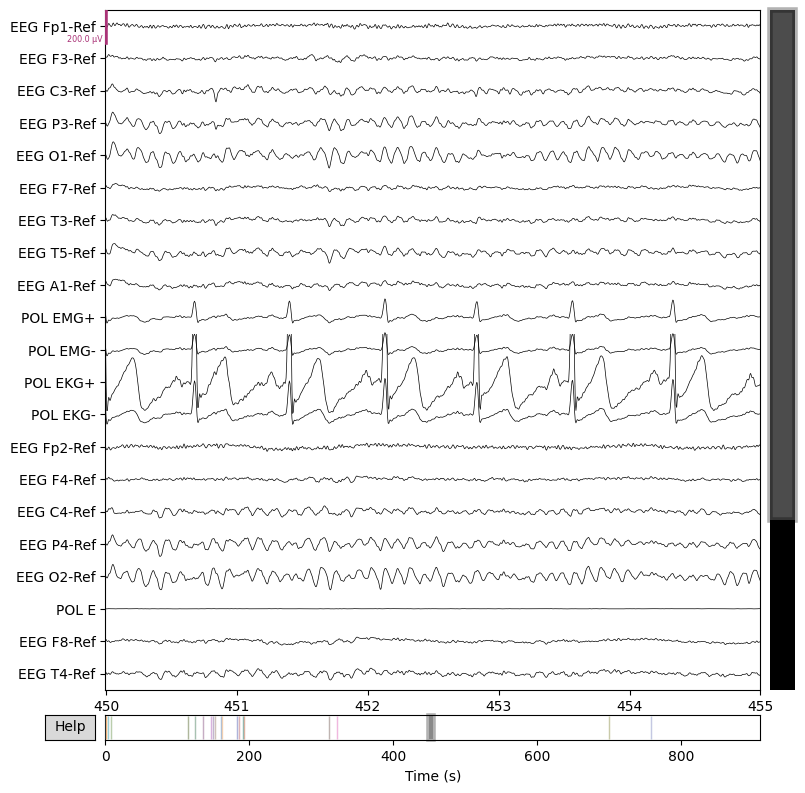

In [9]:
midpoint = raw.times[-1] / 2  # Total duration divided by 2
# Plot from the midpoint
raw.plot(duration=5, n_channels=21, block=True, scalings=0.0001, start=midpoint - 5)  # 5 seconds before the midpoint

In [20]:

channel_names = raw.info['ch_names']

# Print the channel names
print("Channels in the EDF file:")
for idx, channel in enumerate(channel_names, start=1):
    print(f"{idx}: {channel}")


Channels in the EDF file:
1: EEG Fp1-Ref
2: EEG F3-Ref
3: EEG C3-Ref
4: EEG P3-Ref
5: EEG O1-Ref
6: EEG F7-Ref
7: EEG T3-Ref
8: EEG T5-Ref
9: EEG A1-Ref
10: POL EMG+
11: POL EMG-
12: POL EKG+
13: POL EKG-
14: EEG Fp2-Ref
15: EEG F4-Ref
16: EEG C4-Ref
17: EEG P4-Ref
18: EEG O2-Ref
19: POL E
20: EEG F8-Ref
21: EEG T4-Ref
22: EEG T6-Ref
23: EEG A2-Ref
24: EEG FZ-Ref
25: EEG CZ-Ref
26: EEG PZ-Ref
27: POL $A11
28: POL $A12


In [21]:

channels_to_keep = ['EEG Fp1-Ref', 'EEG F3-Ref', 'EEG C3-Ref','EEG P3-Ref','EEG O1-Ref','EEG F7-Ref','EEG T3-Ref','EEG T5-Ref','EEG Fp2-Ref','EEG F4-Ref','EEG C4-Ref','EEG P4-Ref','EEG O2-Ref','EEG F8-Ref','EEG T4-Ref','EEG T6-Ref','EEG FZ-Ref','EEG CZ-Ref','EEG PZ-Ref']
raw.pick(channels_to_keep)
# raw.save('filtered_channels_raw.fif', overwrite=True
len(channels_to_keep)


19

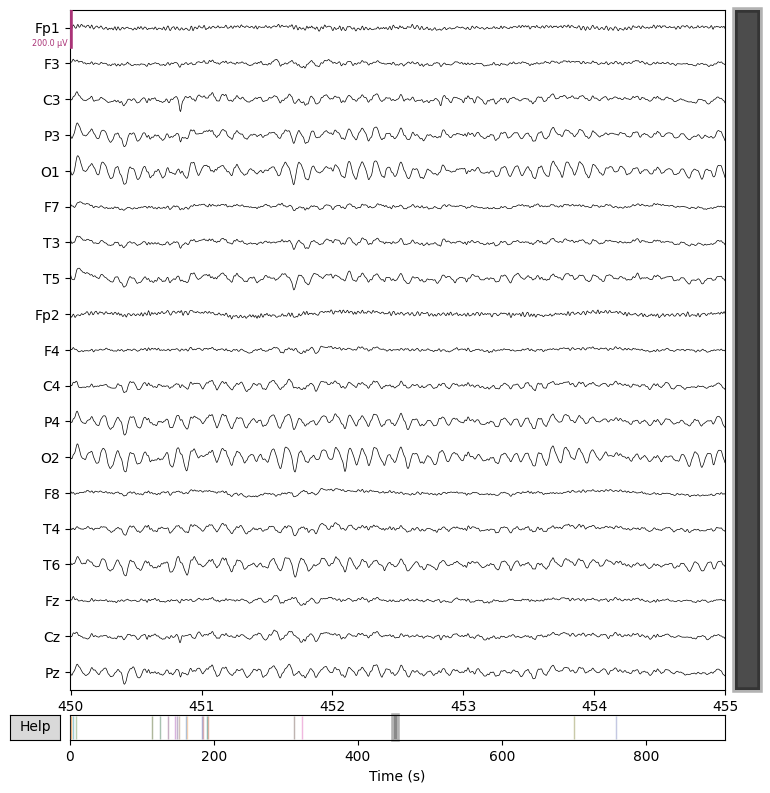

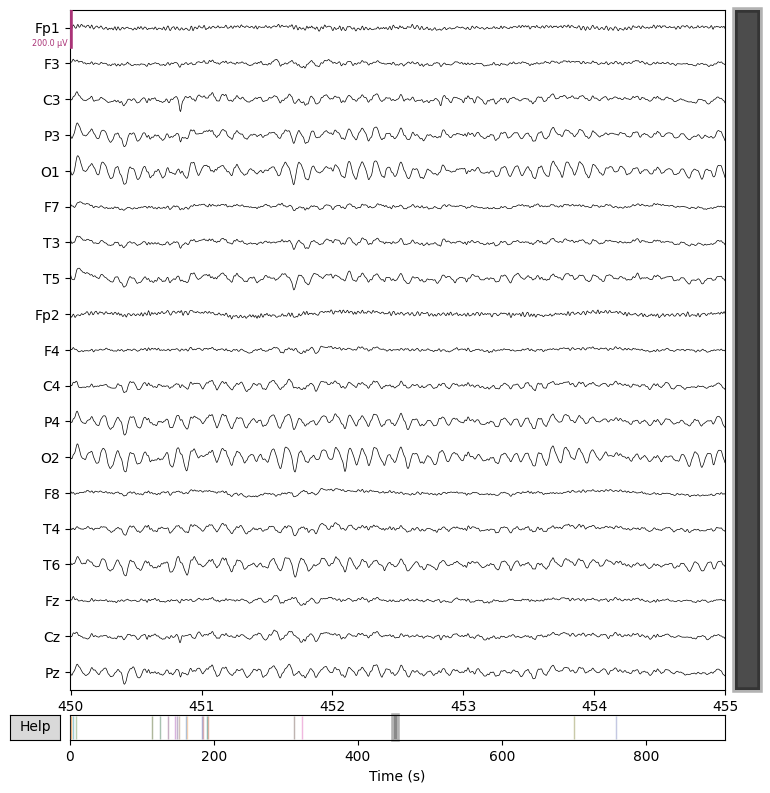

In [22]:
channel_rename= {
    'EEG Fp1-Ref': 'Fp1',
    'EEG Fp2-Ref': 'Fp2',
    'EEG F7-Ref': 'F7',
    'EEG F3-Ref': 'F3',
    'EEG FZ-Ref': 'Fz',
    'EEG F4-Ref': 'F4',
    'EEG F8-Ref': 'F8',
    'EEG C3-Ref': 'C3',
    'EEG CZ-Ref': 'Cz',
    'EEG C4-Ref': 'C4',
    'EEG P3-Ref': 'P3',
    'EEG PZ-Ref': 'Pz',
    'EEG P4-Ref': 'P4',
    'EEG T3-Ref': 'T3',
    'EEG T4-Ref': 'T4',
    'EEG T5-Ref': 'T5',
    'EEG T6-Ref': 'T6',
    'EEG O1-Ref': 'O1',
    'EEG O2-Ref': 'O2',
    'EEG A1-Ref': 'A1',
    'EEG A2-Ref': 'A2',
}

valid_renames = {k: v for k, v in channel_rename.items() if k in raw.ch_names}
raw.rename_channels(valid_renames)

raw.set_montage('standard_1020', on_missing='raise')

midpoint = raw.times[-1] / 2  # Total duration divided by 2
# Plot from the midpoint
raw.plot(duration=5, n_channels=21, block=True, scalings=0.0001, start=midpoint - 5)  # 5 seconds before the midpoint



EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


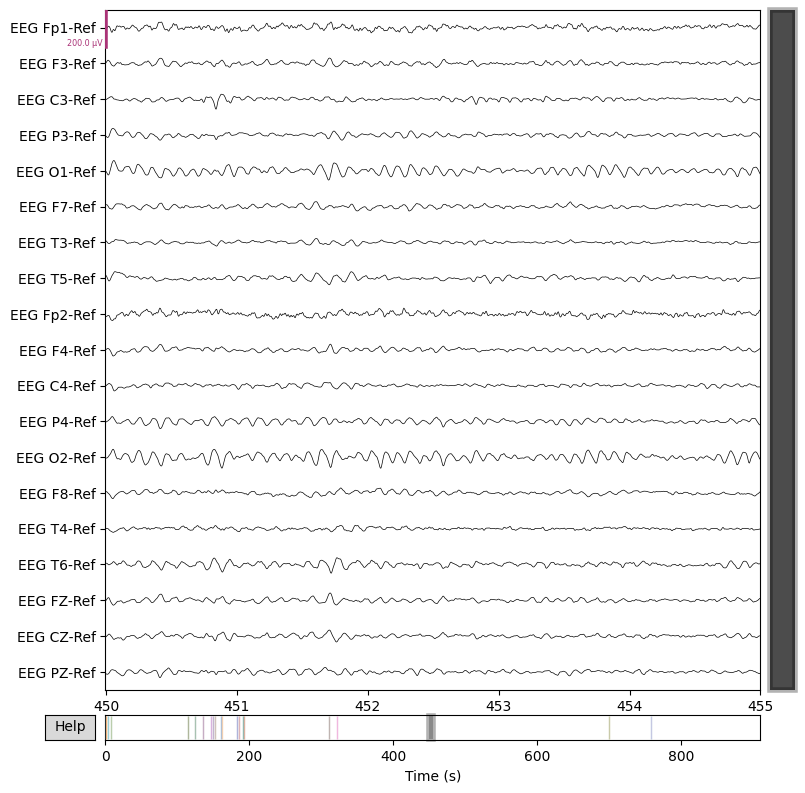

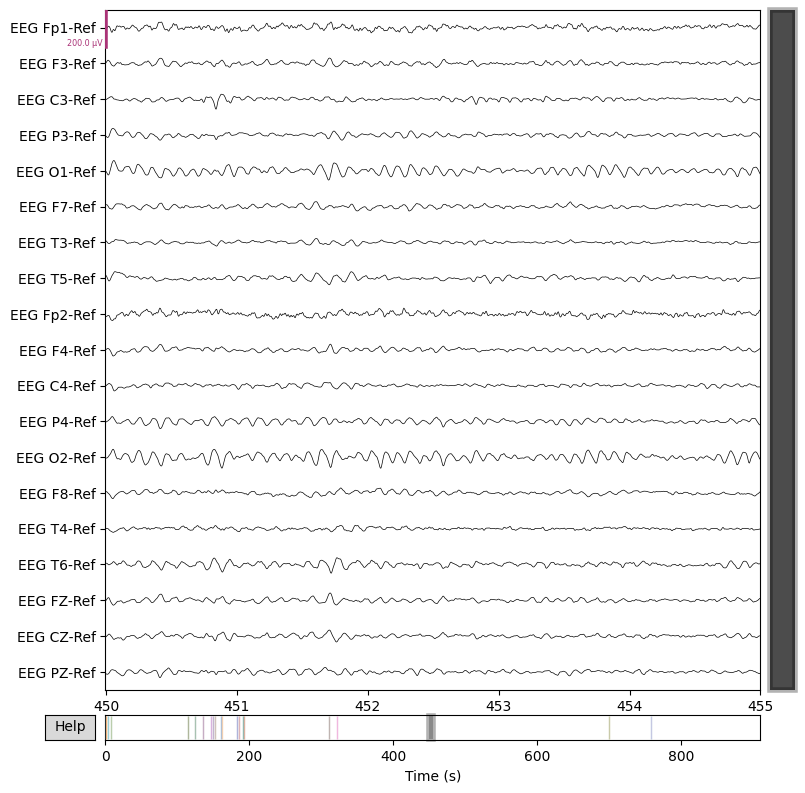

In [12]:
# raw.filter(
#     l_freq=0.5,  # Lower bound of the stop band
#     h_freq=50,  # Upper bound of the stop band
#     method='iir',
#     iir_params={'order': 4, 'ftype': 'butter'},  # 4th-order Butterworth filter
#     picks=None  # Apply to all data channels (default)
# )

# raw.set_eeg_reference(ref_channels='average')

# midpoint = raw.times[-1] / 2  # Total duration divided by 2
# # Plot from the midpoint
# raw.plot(duration=5, n_channels=19, block=True, scalings=0.0001, start=midpoint - 5)  # 5 seconds before the midpoint


Fitting ICA to data using 19 channels (please be patient, this may take a while)


<ipython-input-23-9e5065cd6139>:7: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(raw)


Selecting by number: 19 components
Fitting ICA took 6.2s.


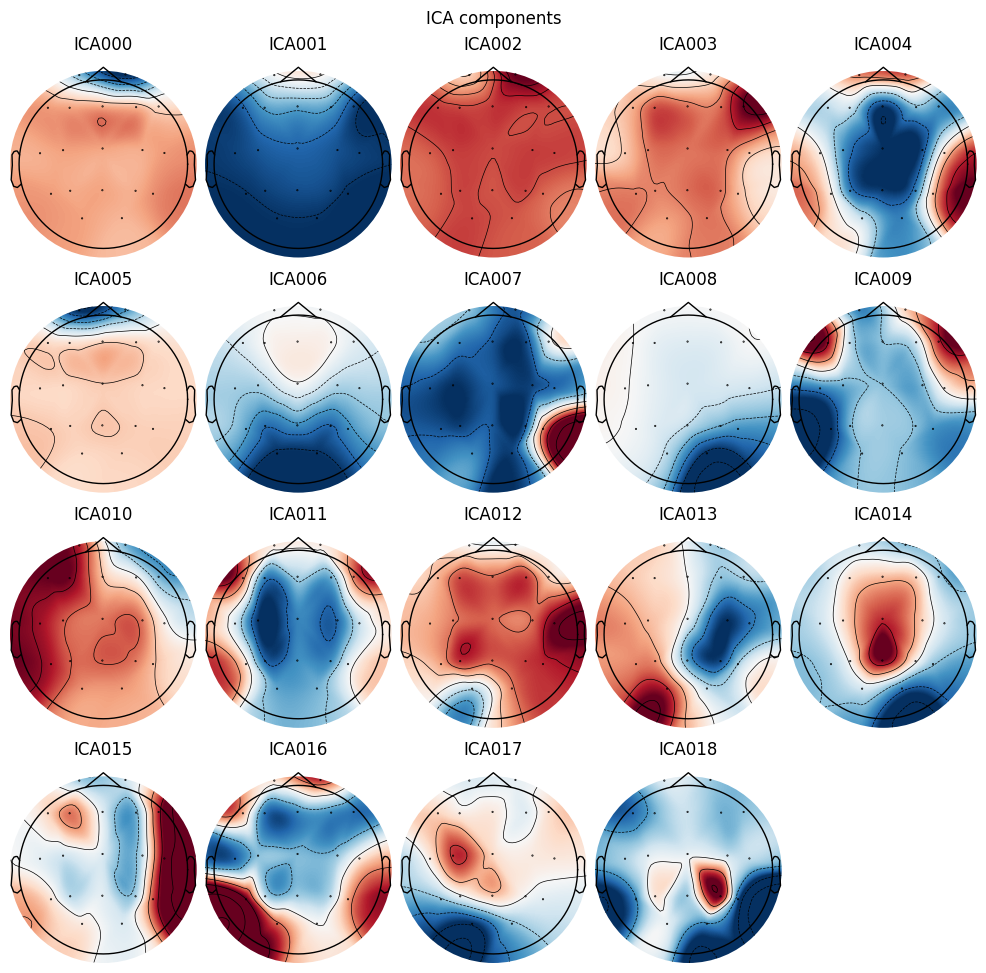

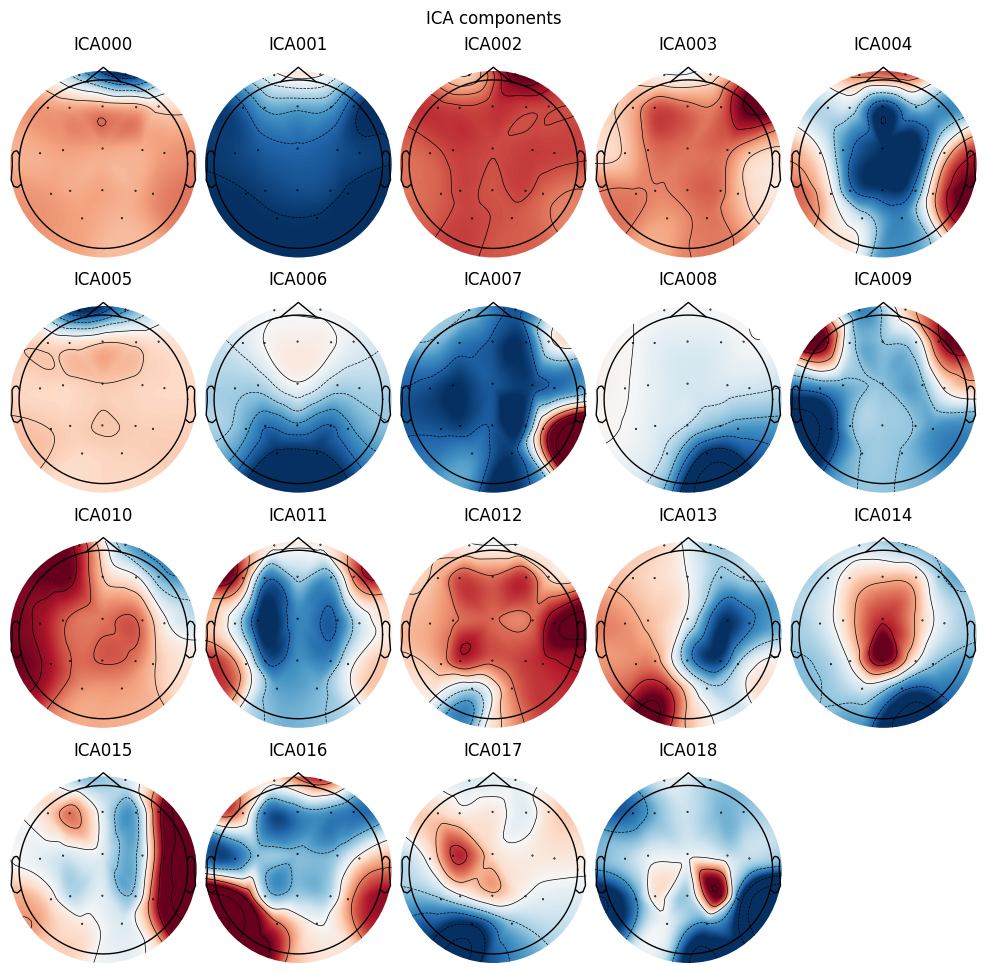

In [23]:

from mne.preprocessing import ICA, create_eog_epochs


# Create and fit the ICA
ica = ICA(n_components=19 , random_state=None, max_iter=800)

ica.fit(raw)
# sources = ica.transform(raw)

# Plot the components
ica.plot_components()



Creating RawArray with float64 data, n_channels=19, n_times=60001
    Range : 91000 ... 151000 =    455.000 ...   755.000 secs
Ready.


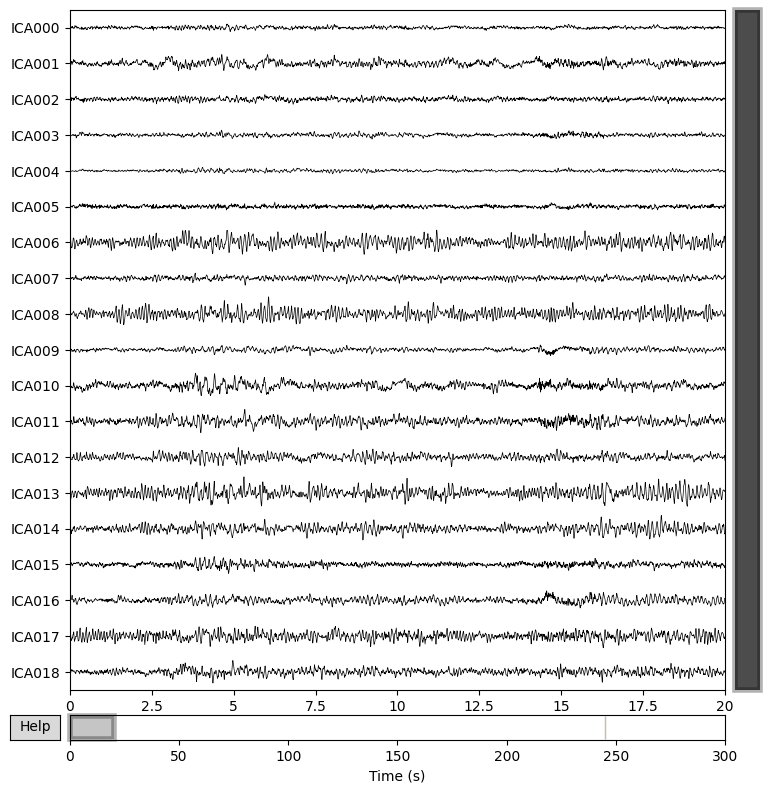

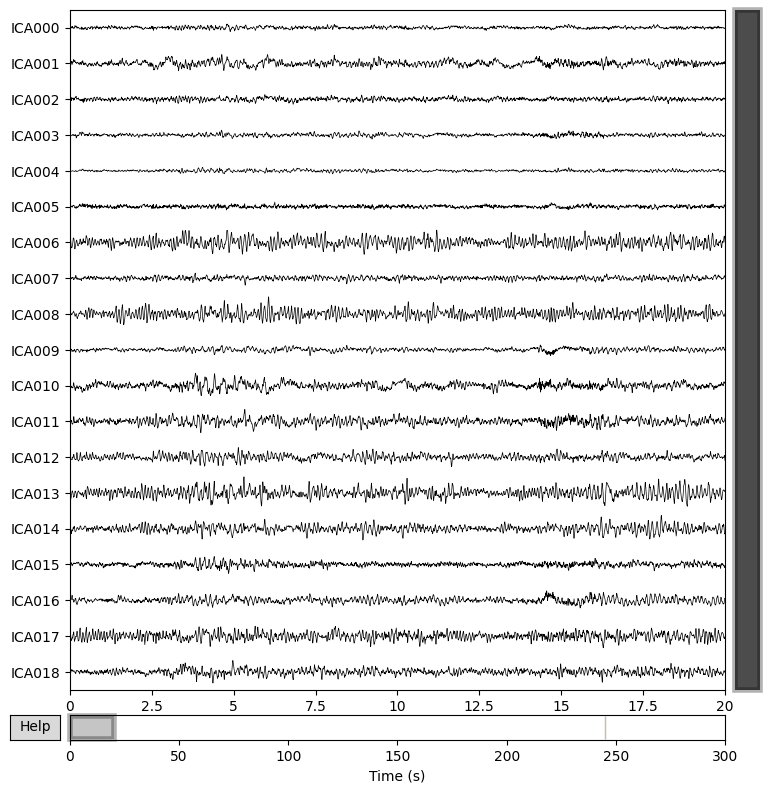

In [24]:
# Calculate the middle of the recording
duration = raw.times[-1]  # Total duration in seconds
middle_time = duration / 2  # Middle point in seconds

# Create a cropped version of the raw data around the middle
cropped_raw = raw.copy().crop(tmin=middle_time, tmax=middle_time + 300)  # 5 seconds window

# Plot ICA sources on the cropped data
ica.plot_sources(cropped_raw)


In [ ]:
# Calculate the middle of the recording
# duration = raw.times[-1]  # Total duration in seconds
# middle_time = duration / 2  # Middle point in seconds

# Plot ICA components from the middle of the recording
# ica.plot_sources(raw, start=middle_time, duration=5)

# # Visualize topographies of the components (without the title argument)
ica.plot_properties(raw, picks=range(ica.n_components_))

In [25]:
ica.exclude = [8]  # Adjust based on your findings
raw_cleaned =ica.apply(raw)  # Apply ICA to remove the excluded components
# ica.plot_properties(raw, picks=range(ica.n_components_))
# ica.plot_sources(raw)


Applying ICA to Raw instance
    Transforming to ICA space (19 components)
    Zeroing out 1 ICA component
    Projecting back using 19 PCA components


In [ ]:
d = raw_cleaned.get_data()
def NormalizeData(data):
    return (data - np.min(data)) / (np.max(data) - np.min(data))

n = NormalizeData(d)
for i in range(0,18):
    print(d[i].max(),d[i].min())
    print(n[i].max(),n[i].min())

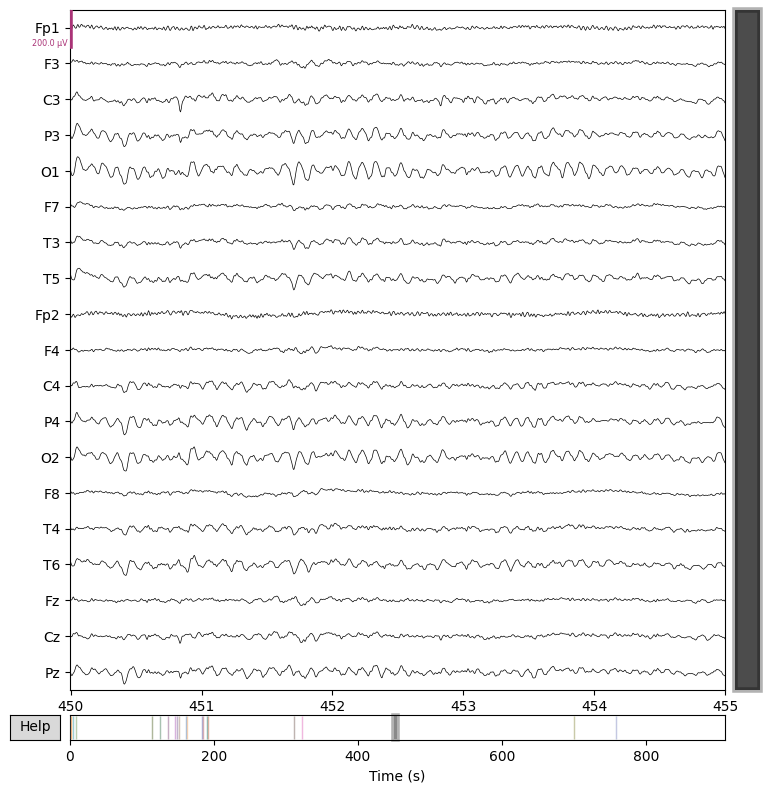

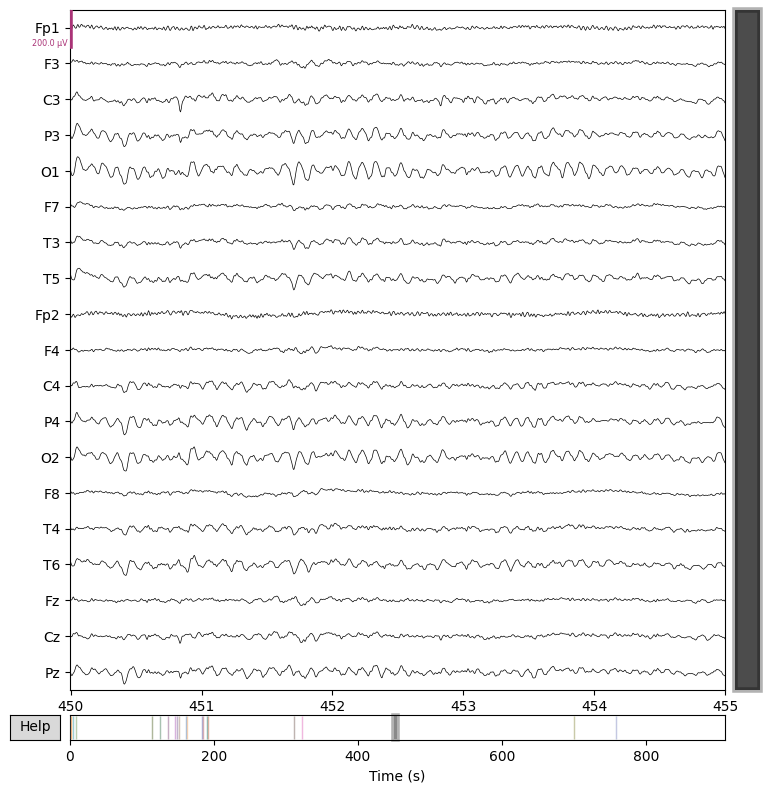

In [26]:
# midpoint =raw_cleaned.times[-1] / 2  # Total duration divided by 2

# Plot from the midpoint
raw_cleaned.plot(duration=5, n_channels=19, block=True, scalings=0.0001x , start=midpoint - 5)  # 5 seconds before the midpoint

In [ ]:
pip install edfio
# Save the cleaned data to an EDF file
output_file = "cleaned_data.edf"
raw.export(output_file, fmt='edf')


In [ ]:
from google.colab import files

# Specify the path to your file
file_path = '/content/your_file_name.extension'

# Download the file
files.download(file_path)


In [ ]:
import shutil

# Specify the folder to zip and the output zip file name
folder_to_zip = "/content/folder_name"
output_zip_file = "/content/folder_name.zip"

# Zip the folder
shutil.make_archive(output_zip_file.replace('.zip', ''), 'zip', folder_to_zip)

print(f"Folder zipped at: {output_zip_file}")



In [ ]:
from google.colab import files

# Specify the zip file to download
files.download(output_zip_file)